## **_Noah Smith - HOMEWORK ASSIGNMENT_** 2!!!!!!

**_Question #1_** : Are any of the interaction or second order terms statistically significant?

['TV', 'Radio', 'Newspaper', 'Sales']
(200, 4)
      TV  Radio  Newspaper  Sales
0  230.1   37.8       69.2   22.1
1   44.5   39.3       45.1   10.4
2   17.2   45.9       69.3   12.0
3  151.5   41.3       58.5   16.5
4  180.8   10.8       58.4   17.9
                            OLS Regression Results                            
Dep. Variable:                  Sales   R-squared:                       0.903
Model:                            OLS   Adj. R-squared:                  0.901
Method:                 Least Squares   F-statistic:                     605.4
Date:                Fri, 02 Oct 2026   Prob (F-statistic):           8.13e-99
Time:                        17:01:03   Log-Likelihood:                -383.34
No. Observations:                 200   AIC:                             774.7
Df Residuals:                     196   BIC:                             787.9
Df Model:                           3                                         
Covariance Type:            nonrobust 

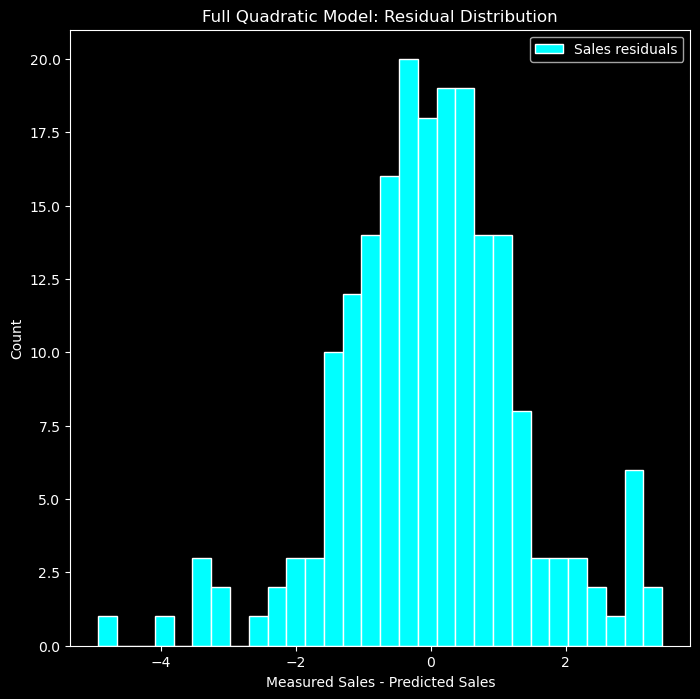

count    2.000000e+02
mean     6.179945e-14
std      1.341886e+00
min     -4.922012e+00
25%     -7.703587e-01
50%      2.282547e-02
75%      8.061922e-01
max      3.424282e+00
Name: Quadratic_Residual, dtype: float64

Linear:    R^2 = 0.9026, adj R^2 = 0.9011, resid std = 1.6491
Quadratic: R^2 = 0.9355, adj R^2 = 0.9325, resid std = 1.3419


In [4]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import statsmodels.formula.api as smf

advert = pd.read_csv('../Week3/advertising.csv')

advert = advert.drop(columns=[c for c in advert.columns if str(c).startswith('Unnamed')])
advert.columns = advert.columns.str.strip().str.lower()
advert = advert.rename(columns={'tv': 'TV', 'radio': 'Radio',
                                'newspaper': 'Newspaper', 'sales': 'Sales'})
print(advert.columns.tolist())
print(advert.shape)
print(advert.head())

linear_formula = 'Sales ~ TV + Radio + Newspaper'
model_linear = smf.ols(linear_formula, data=advert).fit()

advert['Sales_Linear'] = model_linear.predict()
advert['Linear_Residual'] = advert['Sales'] - advert['Sales_Linear']
print(model_linear.summary())
print("Linear residual std:", advert['Linear_Residual'].std())

quadratic_formula = ('Sales ~ TV + Radio + Newspaper + np.power(TV, 2) + '
                     'np.power(Radio, 2) + np.power(Newspaper, 2) + '
                     'TV:Radio + TV:Newspaper + Radio:Newspaper')
model_quadratic = smf.ols(quadratic_formula, data=advert).fit()

advert['Sales_Quadratic'] = model_quadratic.predict()
advert['Quadratic_Residual'] = advert['Sales'] - advert['Sales_Quadratic']
print(model_quadratic.summary())

p = model_quadratic.pvalues.drop('Intercept')
print("Significant (P < 0.05):")
print(p[p < 0.05].sort_values())
print("\nNot significant:")
print(p[p >= 0.05].sort_values())

fig, ax = plt.subplots(1, 1, figsize=(8, 8))
ax.hist(advert['Quadratic_Residual'], color='cyan', ec='white', bins=30,
        label='Sales residuals')
ax.set_title('Full Quadratic Model: Residual Distribution')
ax.set_xlabel('Measured Sales - Predicted Sales')
ax.set_ylabel('Count')
ax.legend()
plt.show()

print(advert['Quadratic_Residual'].describe())
print(f"\nLinear:    R^2 = {model_linear.rsquared:.4f}, "
      f"adj R^2 = {model_linear.rsquared_adj:.4f}, "
      f"resid std = {advert['Linear_Residual'].std():.4f}")
print(f"Quadratic: R^2 = {model_quadratic.rsquared:.4f}, "
      f"adj R^2 = {model_quadratic.rsquared_adj:.4f}, "
      f"resid std = {advert['Quadratic_Residual'].std():.4f}")

Three of the interaction/second-order terms are statistically significant (p < 0.05):

    1. TV:radio     1.118946e-06
    2. TV^2         1.526880e-11
    3. radio^2      1.909484e-03

**_Question 2_**: Full Linear Regression Analysis

Step 2 first to make step 1 easier

In [5]:
import statsmodels.formula.api as smf


data = pd.read_csv('..//Week3/auto-mpg.csv')
data.columns = data.columns.str.strip().str.lower().str.replace(' ', '_')
print(data.columns.tolist())
print(data.head())

for col in data.columns:
    data[col] = pd.to_numeric(data[col], errors='coerce')

horse_med = data['horsepower'].median()
data['horsepower'] = data['horsepower'].fillna(horse_med)

data = data.drop(columns=['car_name'])
print(data.isna().sum())
print(data.shape)

['mpg', 'cylinders', 'displacement', 'horsepower', 'weight', 'acceleration', 'model_year', 'origin', 'car_name']
    mpg  cylinders  displacement horsepower  weight  acceleration  model_year  \
0  18.0          8         307.0        130    3504          12.0          70   
1  15.0          8         350.0        165    3693          11.5          70   
2  18.0          8         318.0        150    3436          11.0          70   
3  16.0          8         304.0        150    3433          12.0          70   
4  17.0          8         302.0        140    3449          10.5          70   

   origin                   car_name  
0       1  chevrolet chevelle malibu  
1       1          buick skylark 320  
2       1         plymouth satellite  
3       1              amc rebel sst  
4       1                ford torino  
mpg             0
cylinders       0
displacement    0
horsepower      0
weight          0
acceleration    0
model_year      0
origin          0
dtype: int64
(398, 8)


Step 1

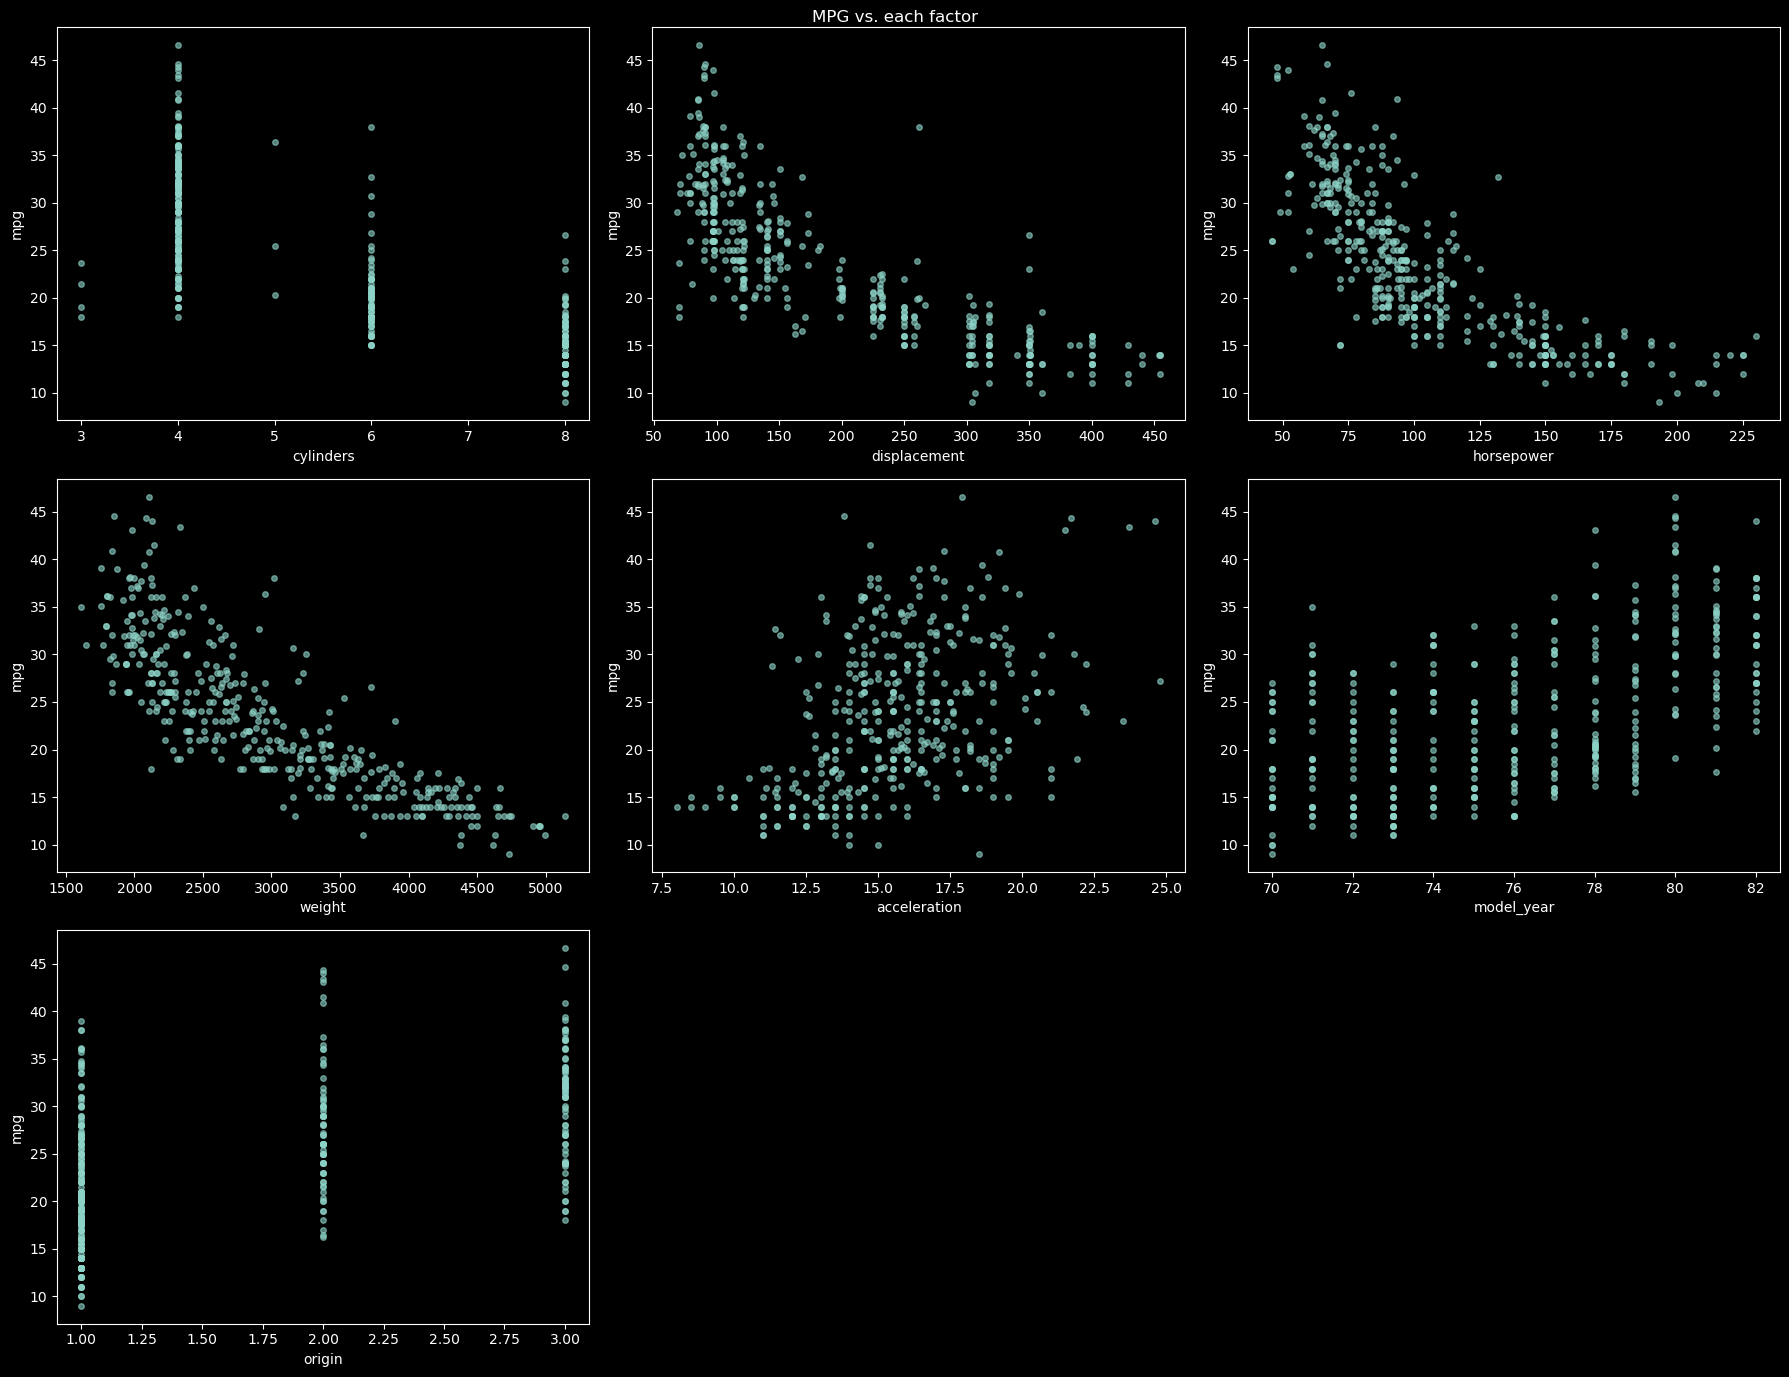

In [6]:
factors = ['cylinders', 'displacement', 'horsepower', 'weight',
           'acceleration', 'model_year', 'origin']

fig, ax = plt.subplots(3, 3, figsize=(18, 14))
fig.suptitle("MPG vs. each factor")
for a, f in zip(ax.ravel(), factors):
    a.plot(data[f], data['mpg'], 'o', ms=4, alpha=0.6)
    a.set_xlabel(f)
    a.set_ylabel('mpg')
for a in ax.ravel()[len(factors):]:
    a.axis('off')
plt.tight_layout()
plt.show()



Step 3

In [7]:
for f in factors:
    data[f + '_n'] = (data[f] - data[f].mean()) / data[f].std()

print(data[[f + '_n' for f in factors]].isna().sum())   # all zeros
print(data[[f + '_n' for f in factors]].describe().loc[['mean', 'std']])

cylinders_n       0
displacement_n    0
horsepower_n      0
weight_n          0
acceleration_n    0
model_year_n      0
origin_n          0
dtype: int64
       cylinders_n  displacement_n  horsepower_n      weight_n  \
mean -1.785283e-17             0.0 -3.570567e-17 -1.606755e-16   
std   1.000000e+00             1.0  1.000000e+00  1.000000e+00   

      acceleration_n  model_year_n      origin_n  
mean   -2.499397e-16 -2.070929e-15  1.785283e-17  
std     1.000000e+00  1.000000e+00  1.000000e+00  


Step 4: Linear Model

                            OLS Regression Results                            
Dep. Variable:                    mpg   R-squared:                       0.821
Model:                            OLS   Adj. R-squared:                  0.818
Method:                 Least Squares   F-statistic:                     255.4
Date:                Fri, 02 Oct 2026   Prob (F-statistic):          2.15e-141
Time:                        17:01:03   Log-Likelihood:                -1040.3
No. Observations:                 398   AIC:                             2097.
Df Residuals:                     390   BIC:                             2128.
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
Intercept         23.5146      0.167    140.

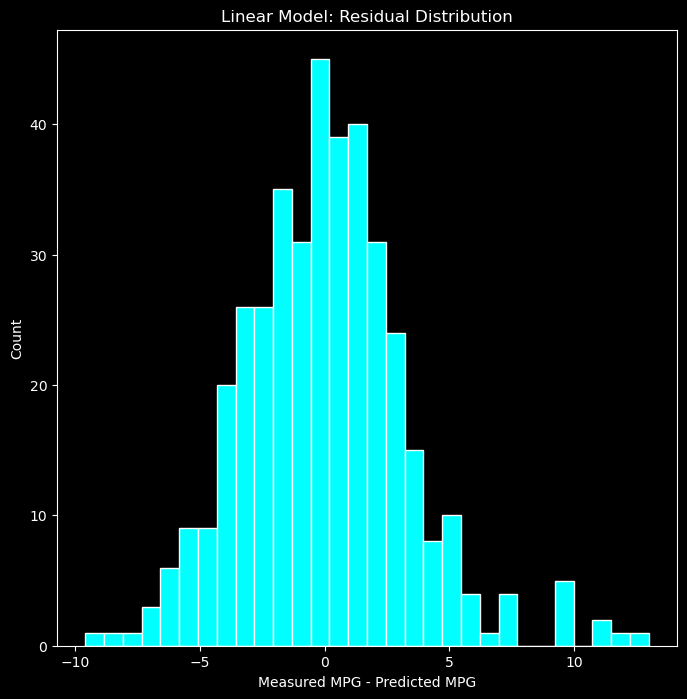

count    3.980000e+02
mean     1.588902e-14
std      3.307309e+00
min     -9.595791e+00
25%     -2.154691e+00
50%     -1.183496e-01
75%      1.911818e+00
max      1.299423e+01
Name: Linear_Residual, dtype: float64
Linear residual std: 3.3073092094541714


In [8]:
linear_formula = ('mpg ~ cylinders_n + displacement_n + horsepower_n + weight_n + '
                  'acceleration_n + model_year_n + origin_n')
model_linear = smf.ols(linear_formula, data=data).fit()

data['MPG_Linear'] = model_linear.predict()
data['Linear_Residual'] = data['mpg'] - data['MPG_Linear']
print(model_linear.summary())

fig, ax = plt.subplots(1, 1, figsize=(8, 8))
ax.hist(data['Linear_Residual'], color='cyan', ec='white', bins=30)
ax.set_title('Linear Model: Residual Distribution')
ax.set_xlabel('Measured MPG - Predicted MPG')
ax.set_ylabel('Count')
plt.show()

print(data['Linear_Residual'].describe())
print("Linear residual std:", data['Linear_Residual'].std())

Step 5: Only sig terms

Significant linear terms kept: ['displacement_n', 'weight_n', 'model_year_n', 'origin_n']
Dropped: ['cylinders_n', 'horsepower_n', 'acceleration_n']
mpg ~ displacement_n + weight_n + model_year_n + origin_n
                            OLS Regression Results                            
Dep. Variable:                    mpg   R-squared:                       0.818
Model:                            OLS   Adj. R-squared:                  0.816
Method:                 Least Squares   F-statistic:                     442.2
Date:                Fri, 02 Oct 2026   Prob (F-statistic):          5.29e-144
Time:                        17:01:04   Log-Likelihood:                -1043.3
No. Observations:                 398   AIC:                             2097.
Df Residuals:                     393   BIC:                             2117.
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
   

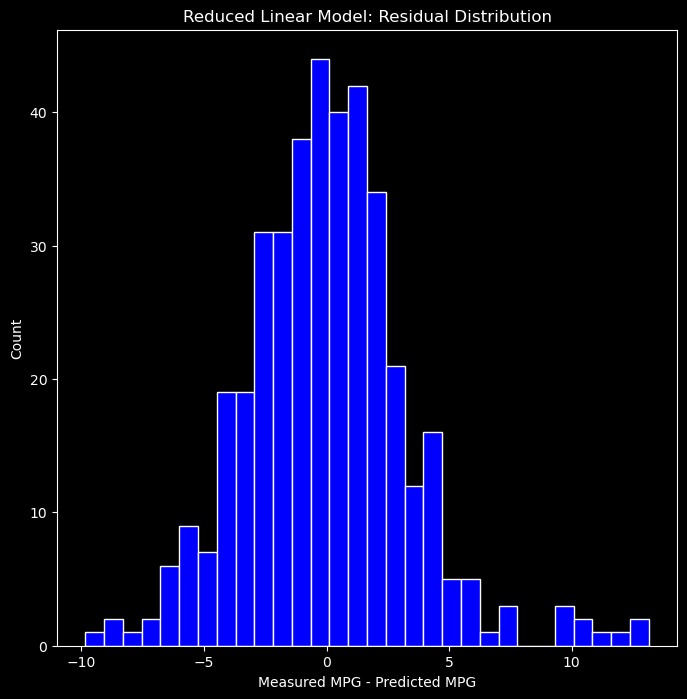

Reduced residual std: 3.3326606747649774


In [9]:
p4 = model_linear.pvalues.drop('Intercept')
keep_lin = [t for t in p4.index if p4[t] < 0.05]
print("Significant linear terms kept:", keep_lin)
print("Dropped:", [t for t in p4.index if t not in keep_lin])

reduced_formula = 'mpg ~ ' + ' + '.join(keep_lin)
print(reduced_formula)

model_reduced = smf.ols(reduced_formula, data=data).fit()
data['MPG_Reduced'] = model_reduced.predict()
data['Reduced_Residual'] = data['mpg'] - data['MPG_Reduced']
print(model_reduced.summary())

fig, ax = plt.subplots(1, 1, figsize=(8, 8))
ax.hist(data['Reduced_Residual'], color='blue', ec='white', bins=30)
ax.set_title('Reduced Linear Model: Residual Distribution')
ax.set_xlabel('Measured MPG - Predicted MPG')
ax.set_ylabel('Count')
plt.show()

print("Reduced residual std:", data['Reduced_Residual'].std())

Step 6: Interaction terms

In [10]:
terms = ('cylinders_n + displacement_n + horsepower_n + weight_n + '
         'acceleration_n + model_year_n + origin_n')
interaction_formula = 'mpg ~ (' + terms + ')**2'
print(interaction_formula)

mpg ~ (cylinders_n + displacement_n + horsepower_n + weight_n + acceleration_n + model_year_n + origin_n)**2


Step 7

Fitted terms (excluding intercept): 28
                            OLS Regression Results                            
Dep. Variable:                    mpg   R-squared:                       0.889
Model:                            OLS   Adj. R-squared:                  0.881
Method:                 Least Squares   F-statistic:                     105.6
Date:                Fri, 02 Oct 2026   Prob (F-statistic):          1.13e-157
Time:                        17:01:04   Log-Likelihood:                -945.09
No. Observations:                 398   AIC:                             1948.
Df Residuals:                     369   BIC:                             2064.
Df Model:                          28                                         
Covariance Type:            nonrobust                                         
                                    coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------

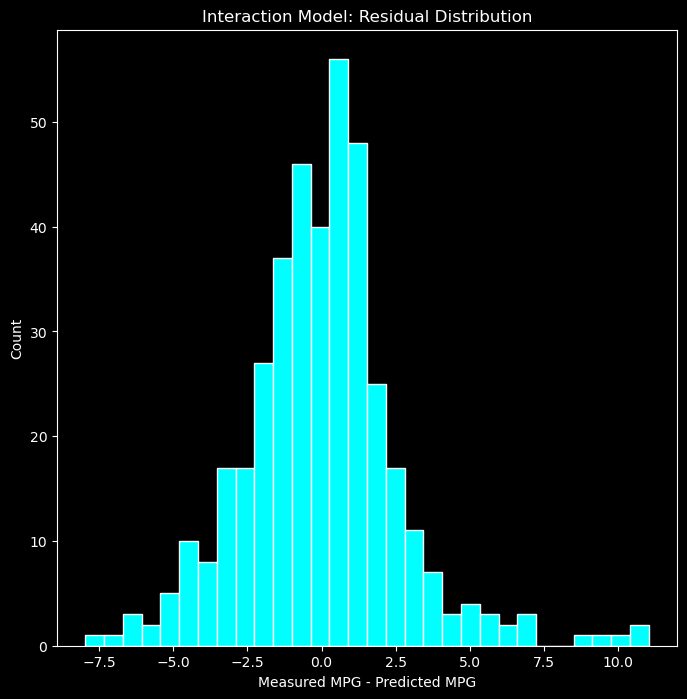

count    3.980000e+02
mean     8.531869e-14
std      2.603662e+00
min     -7.964628e+00
25%     -1.490639e+00
50%      7.584956e-02
75%      1.308353e+00
max      1.102944e+01
Name: Interaction_Residual, dtype: float64
Interaction residual std: 2.603661880875473
Significant interaction terms (P < 0.05):
acceleration_n:origin_n        0.002195
displacement_n:model_year_n    0.012578
acceleration_n:model_year_n    0.015141
displacement_n:weight_n        0.029080
model_year_n:origin_n          0.045864
dtype: float64

Significant linear terms (P < 0.05):
horsepower_n    3.212168e-03
weight_n        1.765231e-14
model_year_n    8.751954e-39
origin_n        1.277474e-02
dtype: float64

Step 4: adj R^2 = 0.8177, resid std = 3.3073
Step 7: adj R^2 = 0.8806, resid std = 2.6037


In [11]:
model_interaction = smf.ols(interaction_formula, data=data).fit()
print("Fitted terms (excluding intercept):", len(model_interaction.params) - 1)   # expect 28

data['MPG_Interaction'] = model_interaction.predict()
data['Interaction_Residual'] = data['mpg'] - data['MPG_Interaction']
print(model_interaction.summary())

fig, ax = plt.subplots(1, 1, figsize=(8, 8))
ax.hist(data['Interaction_Residual'], color='cyan', ec='white', bins=30)
ax.set_title('Interaction Model: Residual Distribution')
ax.set_xlabel('Measured MPG - Predicted MPG')
ax.set_ylabel('Count')
plt.show()

print(data['Interaction_Residual'].describe())
print("Interaction residual std:", data['Interaction_Residual'].std())

p = model_interaction.pvalues.drop('Intercept')
sig_int = p[[name for name in p.index if ':' in name]]
print("Significant interaction terms (P < 0.05):")
print(sig_int[sig_int < 0.05].sort_values())

print("\nSignificant linear terms (P < 0.05):")
print(p[[name for name in p.index if ':' not in name]].loc[lambda s: s < 0.05])

print(f"\nStep 4: adj R^2 = {model_linear.rsquared_adj:.4f}, "
      f"resid std = {data['Linear_Residual'].std():.4f}")
print(f"Step 7: adj R^2 = {model_interaction.rsquared_adj:.4f}, "
      f"resid std = {data['Interaction_Residual'].std():.4f}")

With a lower residual standard deviation and higher adjusted r^2, the step 7 model fits better, but is likely more complex than necessary since only 5 of its 21 terms were significant.

Step 8

                            OLS Regression Results                            
Dep. Variable:                    mpg   R-squared:                       0.878
Model:                            OLS   Adj. R-squared:                  0.875
Method:                 Least Squares   F-statistic:                     253.0
Date:                Fri, 02 Oct 2026   Prob (F-statistic):          7.68e-169
Time:                        17:01:04   Log-Likelihood:                -963.66
No. Observations:                 398   AIC:                             1951.
Df Residuals:                     386   BIC:                             1999.
Df Model:                          11                                         
Covariance Type:            nonrobust                                         
                                  coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------------
Intercept         

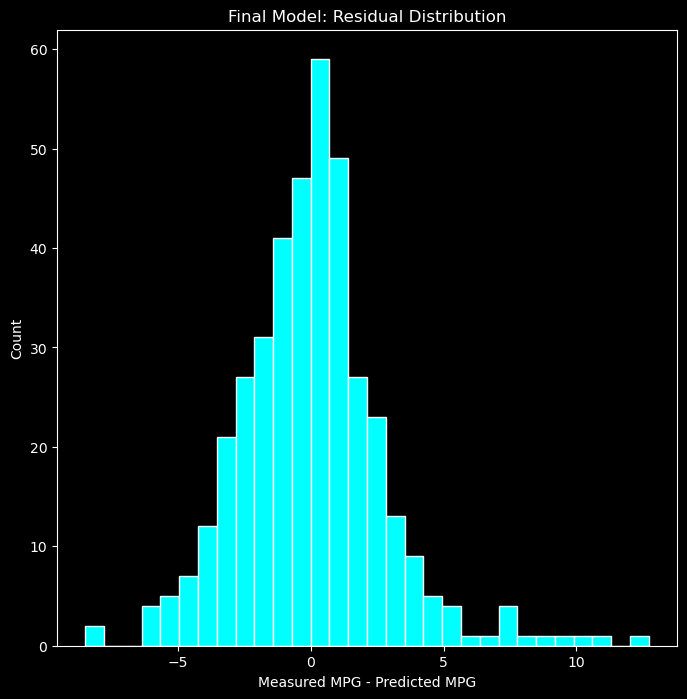

FINAL residual std: 2.727996062847016


In [12]:
final_formula = ('mpg ~ displacement_n + horsepower_n + weight_n + acceleration_n + '
                 'model_year_n + origin_n + displacement_n:weight_n + '
                 'displacement_n:model_year_n + acceleration_n:model_year_n + '
                 'acceleration_n:origin_n + model_year_n:origin_n')
model_final = smf.ols(final_formula, data=data).fit()

data['MPG_Final'] = model_final.predict()
data['Final_Residual'] = data['mpg'] - data['MPG_Final']
print(model_final.summary())

fig, ax = plt.subplots(1, 1, figsize=(8, 8))
ax.hist(data['Final_Residual'], color='cyan', ec='white', bins=30)
ax.set_title('Final Model: Residual Distribution')
ax.set_xlabel('Measured MPG - Predicted MPG')
ax.set_ylabel('Count')
plt.show()

print("FINAL residual std:", data['Final_Residual'].std())